# AutoPilotRL — v1: the driving environment, a random driver and a rule-based driver

## The project
A car learns to drive in traffic **by trial and error**, with **reinforcement learning** (RL): nobody tells it which action is right; it only receives a **reward** after each action and must discover by itself which behaviour maximises the rewards over time.

We use [`highway-env`](https://github.com/Farama-Foundation/HighwayEnv), a set of driving simulations (highway, merge, roundabout, intersection, racetrack, parking). All learning algorithms are written **from scratch in PyTorch**.

| Version | Scenario | Topic |
|---|---|---|
| **v1** | Highway | The RL problem, baselines (random and rule-based drivers), metrics, videos |
| v2 | Simplified highway | Tabular Q-learning |
| v3 | Highway | Deep Q-Network (DQN) |
| v4 | Roundabout, merge, intersection | Double / Dueling DQN, attention over vehicles |
| v5 | Racetrack | Policy gradient: REINFORCE and PPO, continuous steering and throttle |
| v6 | Parking | SAC + Hindsight Experience Replay |
| app | All | Watch the agents drive |

## Reinforcement learning in one picture
At every time step $t$:

$$
\text{state } s_t \;\xrightarrow{\text{agent: policy } \pi}\; \text{action } a_t \;\xrightarrow{\text{environment}}\; \text{reward } r_{t+1},\ \text{next state } s_{t+1}
$$

Formally the problem is a **Markov Decision Process** (MDP) $(\mathcal{S}, \mathcal{A}, P, R, \gamma)$:
- $\mathcal{S}$: the states (here: what the car observes of the traffic around it);
- $\mathcal{A}$: the actions (here: change lane, speed up, slow down…);
- $P(s' \mid s, a)$: how the world evolves (here: the traffic simulator, unknown to the agent);
- $R(s, a)$: the reward;
- $\gamma \in [0, 1)$: the discount factor, how much future rewards count.

The goal is a **policy** $\pi(a \mid s)$ that maximises the expected **return**, the discounted sum of future rewards:

$$
G_t = r_{t+1} + \gamma\, r_{t+2} + \gamma^2 r_{t+3} + \dots = \sum_{k=0}^{\infty} \gamma^k\, r_{t+k+1}
$$

Unlike supervised learning (animal classifier, ChessGPT), there are **no correct answers** to imitate: the agent must **explore** to find out what works, and an action's consequences may only show up many steps later (a lane change now can avoid a crash 5 seconds later).

## What v1 does
No learning yet. We get to know the environment and build the tools that every later version uses:
1. the highway environment: what the car observes, which actions it has, how the reward is computed;
2. an evaluation protocol on **50 fixed traffic scenarios**, with metrics: return, crash rate, speed, distance;
3. videos of the episodes;
4. three simple drivers: **random**, **constant** (always the same action) and **rule-based**, written by hand. These are the baselines that RL must beat.

## Requirements
In the PyCharm terminal, with the project's virtual environment active:
```
pip install torch gymnasium highway-env pygame numpy matplotlib
```
Evaluating the baselines takes a few minutes (the simulation runs on the CPU).

In [1]:
# --- LIBRARIES ---

# Gymnasium: the standard interface for RL environments (reset, step, spaces).
import gymnasium as gym

# Importing highway_env registers its environments in Gymnasium ("highway-fast-v0", ...).
import highway_env

# Numerical computing.
import numpy as np

# Plotting.
import matplotlib.pyplot as plt

# Build GIF animations from frames.
from PIL import Image as PILImage

# Show images and GIFs in the notebook.
from IPython.display import Image, display

# File and folder paths.
from pathlib import Path

# Save the results for the next versions.
import json

# Measure time.
import time

# Folder for the videos.
VIDEO_DIR = Path("videos")

# Create it if needed.
VIDEO_DIR.mkdir(exist_ok=True)

# Folder for the results shared by all versions.
RESULTS_DIR = Path("results")

# Create it if needed.
RESULTS_DIR.mkdir(exist_ok=True)

# Versions, useful if something does not work.
print(f"gymnasium {gym.__version__} | numpy {np.__version__}")

gymnasium 1.4.0 | numpy 2.5.4


## Step 1 — The highway environment

We use `highway-fast-v0`: a 3-lane highway with 20 other vehicles. The other cars are driven by classic traffic models: they keep a safe distance (IDM, *Intelligent Driver Model*) and change lane when convenient (MOBIL). Our car is the **ego vehicle**, the green one in the pictures.

| Setting | Value | Meaning |
|---|---|---|
| `lanes_count` | 3 | number of lanes |
| `vehicles_count` | 20 | other vehicles |
| `duration` | 30 s | an episode lasts at most 30 seconds |
| `policy_frequency` | 1 Hz | the agent decides once per second: at most **30 decisions** per episode |
| `simulation_frequency` | 5 Hz | the physics is simulated 5 times per second between two decisions |

Every environment has the same interface:

```python
obs, info = env.reset(seed=...)                            # start an episode
obs, reward, terminated, truncated, info = env.step(a)     # one action, one time step
```

- `terminated`: the episode ended by itself (**crash**);
- `truncated`: the time limit was reached (30 s).

The cell creates the environment, prints its settings and shows the first frame.

lanes_count            3
vehicles_count         20
duration               30
policy_frequency       1
simulation_frequency   5
reward_speed_range     [20, 30]


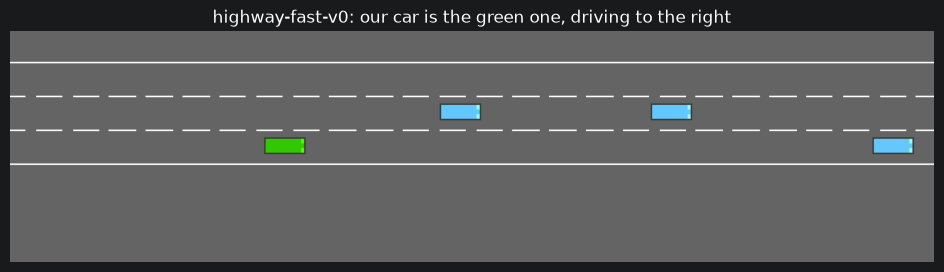

In [2]:
# --- CREATE THE ENVIRONMENT ---

# Name of the environment (the "fast" version: fewer cars and fewer simulation steps, quicker to run).
ENV_NAME = "highway-fast-v0"

# Environment without rendering, for fast evaluations.
env = gym.make(ENV_NAME)

# Same environment with rendering to images ("rgb_array"), for pictures and videos.
env_render = gym.make(ENV_NAME, render_mode="rgb_array")

# The underlying highway-env object (gym.make wraps it in a few checker wrappers).
config = env.unwrapped.config

# Print the main settings.
for key in ["lanes_count", "vehicles_count", "duration", "policy_frequency", "simulation_frequency", "reward_speed_range"]:

    # One setting per line.
    print(f"{key:<22} {config[key]}")

# Start an episode with a fixed seed (same traffic every time).
obs, info = env_render.reset(seed=0)

# Picture of the starting situation.
frame = env_render.render()

# Show it.
plt.figure(figsize=(12, 3))

# The image.
plt.imshow(frame)

# No axes.
plt.axis("off")

# Title.
plt.title("highway-fast-v0: our car is the green one, driving to the right")

# Render.
plt.show()

## Step 2 — What the car observes

The observation is a small table, **Kinematics**: the ego vehicle and the 4 nearest vehicles, one row each, with 5 features:

| Feature | Meaning |
|---|---|
| `presence` | 1 if the row contains a vehicle, 0 if empty (fewer than 4 cars nearby) |
| `x`, `y` | position: for the ego, its own; for the others, **relative to the ego** |
| `vx`, `vy` | velocity: for the ego, its own; for the others, relative to the ego |

$$
s_t = \begin{pmatrix}
1 & x_{\text{ego}} & y_{\text{ego}} & v_{x,\text{ego}} & v_{y,\text{ego}} \\
p_1 & \Delta x_1 & \Delta y_1 & \Delta v_{x,1} & \Delta v_{y,1} \\
\vdots & & & & \vdots \\
p_4 & \Delta x_4 & \Delta y_4 & \Delta v_{x,4} & \Delta v_{y,4}
\end{pmatrix} \in \mathbb{R}^{5 \times 5}
$$

By default the values are **normalised** to roughly $[-1, 1]$, which is good for neural networks (v3) but hard to read. So we also show the same observation **in metres and metres per second**, with a second environment configured with `normalize=False`.

A positive $\Delta x$ means the vehicle is **ahead**; $\Delta y$ is the lateral offset (one lane = 4 m; positive = to the right).

In [3]:
# --- THE OBSERVATION ---

# Names of the 5 features (columns).
FEATURES = ["presence", "x", "y", "vx", "vy"]


# Print an observation as a table.
def print_observation(obs, title):
    """obs: (5, 5) array; one row per vehicle."""

    # Title.
    print(title)

    # Header.
    print("            " + "".join(f"{f:>10}" for f in FEATURES))

    # One row per vehicle.
    for i, row in enumerate(obs):

        # The first row is the ego vehicle.
        name = "ego" if i == 0 else f"vehicle {i}"

        # Values with 2 decimals.
        print(f"{name:<12}" + "".join(f"{v:>10.2f}" for v in row))


# The normalised observation of the episode started above.
print_observation(obs, "Normalised observation (what the agent receives):")

# Same environment, with the observation in metres and metres per second.
env_raw = gym.make(ENV_NAME, config={"observation": {"type": "Kinematics", "normalize": False}})

# Same seed, so the same traffic.
obs_raw, _ = env_raw.reset(seed=0)

# Show it.
print_observation(obs_raw, "\nSame observation in metres and m/s:")

Normalised observation (what the agent receives):
              presence         x         y        vx        vy
ego               1.00      0.75      0.67      0.31      0.00
vehicle 1         1.00      0.10     -0.33     -0.05      0.00
vehicle 2         1.00      0.23     -0.33     -0.03      0.00
vehicle 3         1.00      0.36      0.00     -0.01      0.00
vehicle 4         1.00      0.48     -0.33     -0.05      0.00

Same observation in metres and m/s:
              presence         x         y        vx        vy
ego               1.00    150.82      8.00     25.00      0.00
vehicle 1         1.00     20.56     -4.00     -3.88      0.00
vehicle 2         1.00     45.59     -4.00     -2.18      0.00
vehicle 3         1.00     71.76      0.00     -1.19      0.00
vehicle 4         1.00     95.55     -4.00     -3.90      0.00


## Step 3 — Actions and reward

### Actions
The car does not steer directly: it has 5 high-level actions (**meta-actions**), executed by a low-level controller.

| Index | Action | Effect |
|---|---|---|
| 0 | `LANE_LEFT` | change to the left lane |
| 1 | `IDLE` | keep lane and speed |
| 2 | `LANE_RIGHT` | change to the right lane |
| 3 | `FASTER` | raise the target speed (20 → 25 → 30 m/s) |
| 4 | `SLOWER` | lower the target speed |

Important: our car does **not brake by itself**. If it keeps `IDLE` behind a slower car, it crashes into it. Avoiding crashes is entirely the agent's job.

### Reward
At every step, from the `highway-env` source code:

$$
r_{\text{raw}} = -1 \cdot \mathbb{1}[\text{crash}] \;+\; 0.1 \cdot \frac{\text{lane}}{\text{lanes} - 1} \;+\; 0.4 \cdot \operatorname{clip}\!\left(\frac{v - 20}{30 - 20},\, 0,\, 1\right)
$$

then rescaled from $[-1, 0.5]$ to $[0, 1]$ (and set to 0 if the car leaves the road):

$$
r = \frac{r_{\text{raw}} + 1}{1.5}
$$

- Driving at 30 m/s in the **rightmost** lane gives the maximum, $r = 1$; at 20 m/s in the leftmost lane, $r \approx 0.67$.
- A crash gives about 0, **and ends the episode**: the real penalty is losing all the rewards of the remaining seconds.
- With at most 30 decisions per episode, the maximum return is about **30**.

The incentives conflict: going fast pays, but going fast in traffic means more risk. The agent must find the balance.

The cell plays one action of each type from the start of the episode and prints the reward and its components (`info["rewards"]`).

In [4]:
# --- ACTIONS AND REWARD ---

# Names of the actions, in index order.
ACTIONS = ["LANE_LEFT", "IDLE", "LANE_RIGHT", "FASTER", "SLOWER"]

# Action indices, for readable code.
LEFT, IDLE, RIGHT, FASTER, SLOWER = 0, 1, 2, 3, 4

# Number of actions.
print("Action space:", env.action_space)

# Try each action from the same starting situation.
for a, name in enumerate(ACTIONS):

    # Same traffic every time.
    env.reset(seed=0)

    # One step with this action.
    _, reward, terminated, truncated, info = env.step(a)

    # Components of the reward (crash, right lane, speed, on road).
    parts = ", ".join(f"{k.replace('_reward', '')} {v:.2f}" for k, v in info["rewards"].items())

    # Report.
    print(f"{name:<11} reward {reward:.3f} | speed {info['speed']:5.1f} m/s | {parts}")

Action space: Discrete(5)
LANE_LEFT   reward 0.833 | speed  25.0 m/s | collision 0.00, right_lane 0.50, high_speed 0.50, on_road 1.00
IDLE        reward 0.867 | speed  25.0 m/s | collision 0.00, right_lane 1.00, high_speed 0.50, on_road 1.00
LANE_RIGHT  reward 0.867 | speed  25.0 m/s | collision 0.00, right_lane 1.00, high_speed 0.50, on_road 1.00
FASTER      reward 0.982 | speed  29.3 m/s | collision 0.00, right_lane 1.00, high_speed 0.93, on_road 1.00
SLOWER      reward 0.751 | speed  20.7 m/s | collision 0.00, right_lane 1.00, high_speed 0.07, on_road 1.00


## Step 4 — Evaluation protocol and videos

### Fixed test scenarios
Traffic is random, so a single episode says little. Every driver, in this and all the next versions, is evaluated on the **same 50 episodes**: seeds 1000 to 1049. The same seed gives the same initial traffic, so the comparison is fair.

### Metrics
| Metric | Definition |
|---|---|
| **Return** | $\sum_t r_t$ (undiscounted), at most about 30 |
| **Crash rate** | share of episodes that end with a crash |
| **Mean speed** | average speed over the episode, in m/s |
| **Distance** | metres travelled before the end of the episode |
| **Length** | number of decisions before the end (30 = survived the whole episode) |

For evaluation we use the plain sum of rewards ($\gamma = 1$): episodes are short, and it is easy to read. The discount factor $\gamma$ will matter when the agent **learns** (from v2).

A **policy** here is any function `policy(env, obs) -> action`. It receives the environment too, so that the rule-based driver can read the simulator (see Step 6).

### Videos
`highway-env` simulates 5 physics steps per decision. To get a smooth video we record all intermediate frames, not just one per decision. The GIF plays at twice the real speed.

In [5]:
# --- EVALUATION ---

# The 50 fixed test scenarios (also used by the next versions).
EVAL_SEEDS = list(range(1000, 1050))


# Run a policy on the test scenarios and measure it.
def evaluate(policy, seeds=EVAL_SEEDS, env=env):
    """policy(env, obs) -> action. Returns a dict of per-episode arrays."""

    # Per-episode measurements.
    returns, crashes, speeds, distances, lengths = [], [], [], [], []

    # One episode per seed.
    for seed in seeds:

        # Start the episode.
        obs, info = env.reset(seed=seed)

        # Starting position of the ego car (x, along the road).
        x_start = env.unwrapped.vehicle.position[0]

        # Return, speeds and number of steps of this episode.
        episode_return, episode_speeds, steps = 0.0, [], 0

        # Until the episode ends.
        done = False

        # Play.
        while not done:

            # The policy chooses an action.
            action = policy(env, obs)

            # One step in the environment.
            obs, reward, terminated, truncated, info = env.step(action)

            # Accumulate the reward.
            episode_return += reward

            # Record the speed.
            episode_speeds.append(info["speed"])

            # One more decision.
            steps += 1

            # Crash or time limit.
            done = terminated or truncated

        # Store the measurements of this episode.
        returns.append(episode_return)

        # Crashed or not.
        crashes.append(info["crashed"])

        # Average speed.
        speeds.append(np.mean(episode_speeds))

        # Distance travelled.
        distances.append(env.unwrapped.vehicle.position[0] - x_start)

        # Number of decisions.
        lengths.append(steps)

    # Everything as NumPy arrays.
    return {"return": np.array(returns), "crash": np.array(crashes, dtype=float), "speed": np.array(speeds),
            "distance": np.array(distances), "length": np.array(lengths)}


# One line summary of an evaluation.
def summary(name, res):
    """Print the mean of every metric."""

    # Means.
    print(f"{name:<16} return {res['return'].mean():5.2f} | crash rate {res['crash'].mean():5.1%} | "
          f"speed {res['speed'].mean():5.2f} m/s | distance {res['distance'].mean():6.1f} m | length {res['length'].mean():5.2f}")


# --- VIDEOS ---

# Collects the intermediate frames that highway-env renders while an action is being executed.
class FrameRecorder:
    """highway-env calls _capture_frame() at every physics step once it is registered as the 'video wrapper'."""

    # Empty list of frames.
    def __init__(self, env):

        # The environment to render.
        self.env = env

        # Frames collected so far.
        self.frames = []

        # Frame rate (highway-env sets it: twice the simulation frequency, i.e. twice real time).
        self.frames_per_sec = 10

    # Called by highway-env at every intermediate physics step.
    def _capture_frame(self):

        # Render the current image and keep it.
        self.frames.append(self.env.render())


# Play one episode with rendering and save it as a GIF.
def record_episode(policy, seed, filename, env=env_render):
    """Return (path of the GIF, return of the episode, crashed)."""

    # Start the episode.
    obs, info = env.reset(seed=seed)

    # A new recorder for this episode.
    recorder = FrameRecorder(env)

    # First frame (this also creates the viewer, needed for the intermediate frames).
    recorder.frames.append(env.render())

    # Register the recorder, so that highway-env sends it the intermediate frames.
    env.unwrapped.set_record_video_wrapper(recorder)

    # Return of the episode.
    episode_return = 0.0

    # Until the episode ends.
    done = False

    # Play.
    while not done:

        # One decision.
        obs, reward, terminated, truncated, info = env.step(policy(env, obs))

        # Accumulate the reward.
        episode_return += reward

        # Last frame of the step (this also re-enables the intermediate frames for the next step).
        recorder.frames.append(env.render())

        # Crash or time limit.
        done = terminated or truncated

    # Path of the GIF.
    path = VIDEO_DIR / filename

    # Frames as PIL images.
    images = [PILImage.fromarray(f) for f in recorder.frames]

    # Save as an animated GIF: duration of each frame in milliseconds, loop forever.
    images[0].save(path, save_all=True, append_images=images[1:], duration=int(1000 / recorder.frames_per_sec), loop=0)

    # Path, return and crash.
    return path, episode_return, info["crashed"]


# Record an episode and show it in the notebook.
def show_episode(policy, seed, filename, title):
    """Save the GIF, print the outcome and display the animation."""

    # Record it.
    path, episode_return, crashed = record_episode(policy, seed, filename)

    # Outcome.
    print(f"{title}: return {episode_return:.2f}, {'CRASH' if crashed else 'no crash'}  ({path})")

    # The animation.
    display(Image(filename=str(path)))

## Step 5 — The random driver

The simplest baseline: a uniformly random action at every step,

$$
\pi_{\text{random}}(a \mid s) = \frac{1}{|\mathcal{A}|} = \frac{1}{5}
$$

It sets the floor: any driver that learns something must do better. It is also how an RL agent behaves at the very beginning of training, before it knows anything.

random           return  8.37 | crash rate 96.0% | speed 23.46 m/s | distance  266.2 m | length 11.34
(9s)
Random driver, scenario 1000: return 7.53, CRASH  (videos/v1_random.gif)


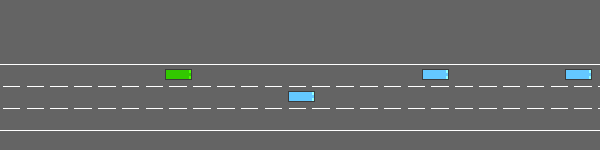

In [6]:
# --- RANDOM DRIVER ---

# Our own random generator (highway-env re-creates its action space at every reset, losing any seed).
rng = np.random.default_rng(0)


# Uniformly random action.
def random_policy(env, obs):
    """Ignore the observation; sample one of the 5 actions."""

    # Random action.
    return int(rng.integers(5))


# Start time.
start = time.perf_counter()

# Evaluate on the 50 test scenarios.
res_random = evaluate(random_policy)

# Report.
summary("random", res_random)

# Time.
print(f"({time.perf_counter() - start:.0f}s)")

# Same random choices in the video.
env_render.action_space.seed(0)

# One episode on video.
show_episode(random_policy, seed=1000, filename="v1_random.gif", title="Random driver, scenario 1000")

## Step 6 — Constant drivers: the speed–safety trade-off

Two policies that always choose the same action:

- **always `IDLE`**: keep lane and speed (25 m/s);
- **always `FASTER`**: accelerate to 30 m/s and stay there.

They show the conflict built into the reward: faster gives more reward per step, but the car does not brake by itself, so it crashes into slower traffic, and a crash costs all the remaining steps.

In [7]:
# --- CONSTANT DRIVERS ---

# Always keep lane and speed.
res_idle = evaluate(lambda env, obs: IDLE)

# Report.
summary("always IDLE", res_idle)

# Always accelerate.
res_faster = evaluate(lambda env, obs: FASTER)

# Report.
summary("always FASTER", res_faster)

always IDLE      return 12.86 | crash rate 92.0% | speed 24.28 m/s | distance  401.6 m | length 16.20
always FASTER    return  7.27 | crash rate 100.0% | speed 28.25 m/s | distance  245.0 m | length  8.38


## Step 7 — A rule-based driver

A driver written by hand, with the rules a human might use. It reads the positions of the cars directly from the **simulator** (`env.unwrapped.road`): the car in front and the car behind, in its own lane and in the lanes next to it.

### Safe distance
The usual **time-headway** rule: keep at least $h$ seconds of distance, plus a margin $d_0$:

$$
d_{\text{safe}} = h \cdot v_{\text{ego}} + d_0, \qquad h = 1.5\ \text{s}, \quad d_0 = 10\ \text{m}
$$

At 25 m/s that is 47.5 m.

### The rules, in order
1. **Too close to the car in front** (gap $< d_{\text{safe}}$):
   - change to the side lane with the **largest free space ahead**, if it is clearly better (at least 10 m more) and **safe behind** (the car behind is at least 12 m away, plus 2 m for every m/s it is faster than us);
   - otherwise `SLOWER`.
2. **Keep right**: if the right lane is safe behind and has more than $2\, d_{\text{safe}}$ free ahead, move right (the reward prefers the right lane).
3. **Free road** (gap $> 2\, d_{\text{safe}}$), or the car in front is not slower than us: `FASTER`.
4. Otherwise `IDLE`.

The thresholds were chosen by hand by trying a few values. This is exactly the weakness of rule-based systems: every number is a manual choice, and rules that work on a highway may fail in a roundabout. RL will learn its own rules from the reward.

Note that this driver has an advantage: it reads exact positions from the simulator, while the RL agents of the next versions will only see the observation of Step 2.

rule-based       return 22.83 | crash rate  2.0% | speed 22.55 m/s | distance  670.4 m | length 29.66
(22s)
Rule-based driver, scenario 1000: return 20.43, no crash  (videos/v1_rules.gif)


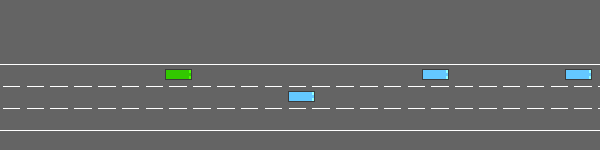

In [8]:
# --- RULE-BASED DRIVER ---

# Time headway in seconds.
HEADWAY = 1.5

# Extra margin in metres.
MARGIN = 10.0


# Hand-written driving rules.
def rule_based_policy(env, obs):
    """Keep a safe distance, overtake when possible, keep right, otherwise slow down."""

    # The simulator objects: road (with all vehicles) and our car.
    road, ego = env.unwrapped.road, env.unwrapped.vehicle

    # The lane our car is in (or moving to): a tuple (start node, end node, lane id).
    lane = ego.target_lane_index

    # Number of lanes.
    n_lanes = env.unwrapped.config["lanes_count"]

    # Gaps to the cars in front and behind in a given lane.
    def gaps(lane_index):
        """Return (gap ahead in m, gap behind in m, car ahead, car behind); inf if there is no car."""

        # Nearest vehicles ahead and behind in that lane.
        front, rear = road.neighbour_vehicles(ego, lane_index)

        # Distance to the car ahead (the road is straight along x).
        gap_front = front.position[0] - ego.position[0] if front else np.inf

        # Distance to the car behind.
        gap_rear = ego.position[0] - rear.position[0] if rear else np.inf

        # All four.
        return gap_front, gap_rear, front, rear

    # Gap ahead in our lane, and the car ahead.
    gap_front, _, front, _ = gaps(lane)

    # Safe distance at the current speed.
    safe = HEADWAY * ego.speed + MARGIN

    # Possible lane changes: (gap ahead, action, safe behind).
    options = []

    # Left lane (id - 1) and right lane (id + 1), if they exist.
    for offset, action in [(-1, LEFT), (1, RIGHT)]:

        # Inside the road.
        if 0 <= lane[2] + offset < n_lanes:

            # Gaps in the side lane.
            side_front, side_rear, _, rear_car = gaps((lane[0], lane[1], lane[2] + offset))

            # Extra space needed if the car behind is faster than us (2 m per m/s).
            extra = 2 * max(0.0, rear_car.speed - ego.speed) if rear_car else 0.0

            # Safe behind?
            rear_ok = side_rear > 12 + extra

            # Store the option.
            options.append((side_front, action, rear_ok))

    # Rule 1: too close to the car in front.
    if gap_front < safe:

        # Side lanes that are safe behind and clearly better ahead.
        better = [o for o in options if o[2] and o[0] > gap_front + 10]

        # Overtake through the best one, or slow down.
        return max(better, key=lambda o: o[0])[1] if better else SLOWER

    # Rule 2: keep right when the right lane is free.
    for side_front, action, rear_ok in options:

        # Right lane, safe behind, plenty of space ahead.
        if action == RIGHT and rear_ok and side_front > 2 * safe:

            # Move right.
            return RIGHT

    # Rule 3: free road, or the car in front is not slower than us.
    if gap_front > 2 * safe or front is None or front.speed >= ego.speed:

        # Speed up.
        return FASTER

    # Rule 4: otherwise keep lane and speed.
    return IDLE


# Start time.
start = time.perf_counter()

# Evaluate on the 50 test scenarios.
res_rules = evaluate(rule_based_policy)

# Report.
summary("rule-based", res_rules)

# Time.
print(f"({time.perf_counter() - start:.0f}s)")

# Same scenario as the random driver, on video.
show_episode(rule_based_policy, seed=1000, filename="v1_rules.gif", title="Rule-based driver, scenario 1000")

## Step 8 — Comparison

Four views of the four drivers:
- **mean return**, the quantity RL will maximise;
- **crash rate**;
- **mean speed**;
- **survival curve**: the share of episodes still running after $t$ decisions. A driver that never crashes stays at 100% until $t = 30$.

random           return  8.37 | crash rate 96.0% | speed 23.46 m/s | distance  266.2 m | length 11.34
always IDLE      return 12.86 | crash rate 92.0% | speed 24.28 m/s | distance  401.6 m | length 16.20
always FASTER    return  7.27 | crash rate 100.0% | speed 28.25 m/s | distance  245.0 m | length  8.38
rule-based       return 22.83 | crash rate  2.0% | speed 22.55 m/s | distance  670.4 m | length 29.66


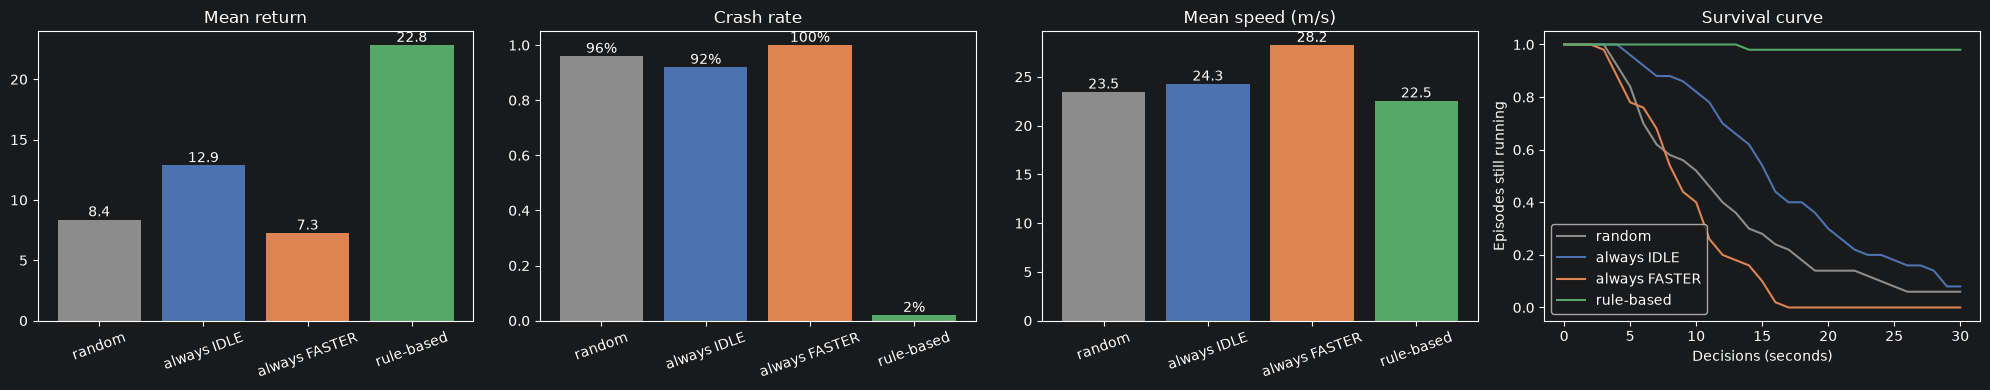

In [9]:
# --- COMPARISON ---

# All results, in display order.
results = {"random": res_random, "always IDLE": res_idle, "always FASTER": res_faster, "rule-based": res_rules}

# Summary table.
for name, res in results.items():

    # One line per driver.
    summary(name, res)

# Colours, one per driver.
colours = ["#8C8C8C", "#4C72B0", "#DD8452", "#55A868"]

# Four panels.
fig, axes = plt.subplots(1, 4, figsize=(20, 4))

# Bar charts of three metrics.
for ax, (metric, label) in zip(axes[:3], [("return", "Mean return"), ("crash", "Crash rate"), ("speed", "Mean speed (m/s)")]):

    # Mean of the metric for each driver.
    values = [res[metric].mean() for res in results.values()]

    # Bars.
    bars = ax.bar(list(results.keys()), values, color=colours)

    # Value on top of each bar (crash rate as a percentage).
    for bar, v in zip(bars, values):

        # Label.
        ax.text(bar.get_x() + bar.get_width() / 2, v, f"{v:.0%}" if metric == "crash" else f"{v:.1f}", ha="center", va="bottom")

    # Title.
    ax.set_title(label)

    # Rotate the names.
    ax.tick_params(axis="x", rotation=20)

# Survival curve: share of episodes that lasted at least t decisions.
t_values = np.arange(0, 31)

# One curve per driver.
for (name, res), colour in zip(results.items(), colours):

    # Share of episodes with length >= t.
    axes[3].plot(t_values, [(res["length"] >= t).mean() for t in t_values], color=colour, label=name)

# Labels.
axes[3].set_xlabel("Decisions (seconds)")

# y-axis label.
axes[3].set_ylabel("Episodes still running")

# Title.
axes[3].set_title("Survival curve")

# Legend.
axes[3].legend()

# Layout.
plt.tight_layout()

# Render.
plt.show()

## Step 9 — Save the baselines

The results are saved to `results/autopilot_results.json`, so that every next version can compare its agents with these baselines on the same 50 scenarios.

In [10]:
# --- SAVE THE RESULTS ---

# Shared results file.
RESULTS_PATH = RESULTS_DIR / "autopilot_results.json"

# Load it if it exists (to keep the results of other versions), otherwise start empty.
results_all = json.loads(RESULTS_PATH.read_text()) if RESULTS_PATH.exists() else {}

# Mean of every metric for every driver of v1.
for name, res in results.items():

    # One entry per driver, prefixed by the version.
    results_all[f"v1 {name}"] = {metric: float(values.mean()) for metric, values in res.items()}

# Write the file.
RESULTS_PATH.write_text(json.dumps(results_all, indent=2))

# Show it.
print(json.dumps(results_all, indent=2))

{
  "v1 random": {
    "return": 8.370935699387102,
    "crash": 0.96,
    "speed": 23.457269934507373,
    "distance": 266.2033590045223,
    "length": 11.34
  },
  "v1 always IDLE": {
    "return": 12.86,
    "crash": 0.92,
    "speed": 24.27783301998197,
    "distance": 401.5511569660505,
    "length": 16.2
  },
  "v1 always FASTER": {
    "return": 7.266217315400074,
    "crash": 1.0,
    "speed": 28.249931999575736,
    "distance": 245.03490353482698,
    "length": 8.38
  },
  "v1 rule-based": {
    "return": 22.829692634204253,
    "crash": 0.02,
    "speed": 22.54953736289873,
    "distance": 670.4171093437227,
    "length": 29.66
  },
  "v2 Q-learning": {
    "return": 23.051447663417385,
    "crash": 0.08,
    "speed": 23.048655246256267,
    "distance": 673.7452053591084,
    "length": 29.24
  }
}


## Results and conclusions

### Summary on the 50 test scenarios
| Driver | Return | Crash rate | Mean speed | Distance | Seconds survived |
|---|---|---|---|---|---|
| Random | 9.18 | 98% | 24.4 m/s | 293 m | 12.1 |
| Always `IDLE` | 12.86 | 92% | 24.3 m/s | 402 m | 16.2 |
| Always `FASTER` | 7.27 | 100% | 28.2 m/s | 245 m | 8.4 |
| **Rule-based** | **22.83** | **2%** | 22.5 m/s | **670 m** | **29.7** |

The maximum possible return is about 30 (30 decisions with reward 1).

### What the baselines show
- **Doing nothing is deadly.** "Always `IDLE`" crashes in 92% of the episodes: our car never brakes by itself, so sooner or later it hits a slower car. The random driver is even worse (98%), and on average its episodes end after 12 seconds.
- **Speed without judgement is the worst option.** "Always `FASTER`" is the fastest driver (28.2 m/s), yet it has the **lowest** return: it crashes every time, after 8 seconds on average. This is the core of the reward: a crash gives about 0 and ends the episode, so the real cost of a crash is **all the rewards of the remaining seconds**.
- **The rule-based driver is safe but slow.** It crashes once in 50 episodes and almost always survives the whole 30 seconds, travelling 2.7 times as far as the random driver. But its average speed (22.5 m/s) is the lowest of all: the 1.5-second headway makes it brake and wait often. The speed component of the reward is almost unused: at 22.5 m/s it is worth $0.4 \times 0.25 = 0.1$ out of a possible 0.4.
- **Survival curve:** the three simple drivers lose most of their episodes within 10–20 seconds, while the rule-based driver stays at 98% until the end.

### Room for learning
On average the rule-based driver collects $22.83 / 29.66 \approx 0.77$ per step, against a maximum of 1. The missing reward is mostly **speed**: a better driver would drive faster while still avoiding crashes, overtaking more decisively and keeping right when possible.

The target for the RL agents of the next versions:
- **return above 22.8 with a crash rate of about 2% or less;**
- using only the **observation** (the 5×5 table), while the rule-based driver reads exact positions from the simulator;
- with no hand-written rules or thresholds: only the reward.

### Next step
**v2, tabular Q-learning:** the agent turns the observation into a small number of discrete situations ("car close ahead, left lane free, …") and learns by trial and error a table $Q(s, a)$: how much return to expect when taking action $a$ in situation $s$.